<a href="https://colab.research.google.com/github/yolohe1210/cse450/blob/main/module3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [17]:
import pandas as pd
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import root_mean_squared_error

data = (
    'https://raw.githubusercontent.com/byui-cse/'
    'cse450-course/master/data/housing.csv'
)
df_train = pd.read_csv(data)
df_train.head()


,id,date,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,...,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15,price
0,1565930130,20141104T000000,4,3.25,3760,4675,2.0,0,0,3,...,2740,1020,2007,0,98038,47.3862,-122.048,3280,4033,429900.0
1,3279000420,20150115T000000,3,1.75,1460,7800,1.0,0,0,2,...,1040,420,1979,0,98023,47.3035,-122.382,1310,7865,233000.0
2,194000575,20141014T000000,4,1.00,1340,5800,1.5,0,2,3,...,1340,0,1914,0,98116,47.5658,-122.389,1900,5800,455000.0
3,2115510160,20141208T000000,3,1.75,1440,8050,1.0,0,0,3,...,1440,0,1985,0,98023,47.3187,-122.390,1790,7488,258950.0
4,7522500005,20140815T000000,2,1.50,1780,4750,1.0,0,0,4,...,1080,700,1947,0,98117,47.6859,-122.395,1690,5962,555000.0


In [18]:
drop_cols = ['id', 'date', 'price']
features = [col for col in df_train.columns if col not in drop_cols]

X = df_train[features]
y = df_train['price']

X_train,X_val,y_train,y_val = train_test_split(X,y,test_size=0.2,random_state=42)

model = XGBRegressor()
model.fit(X_train, y_train)

val_predictions = model.predict(X_val)
rmse = root_mean_squared_error(y_val, val_predictions)
print(f"Validation RMSE: {rmse}")

holdout = (
    'https://raw.githubusercontent.com/byui-cse/'
    'cse450-course/master/data/housing_holdout_test.csv'
)
df_test = pd.read_csv(holdout)

test_predictions = model.predict(df_test[features])

submission = pd.DataFrame({'price': test_predictions})
submission.to_csv('housing_predictions.csv', index=False)

Validation RMSE: 140175.9400660962


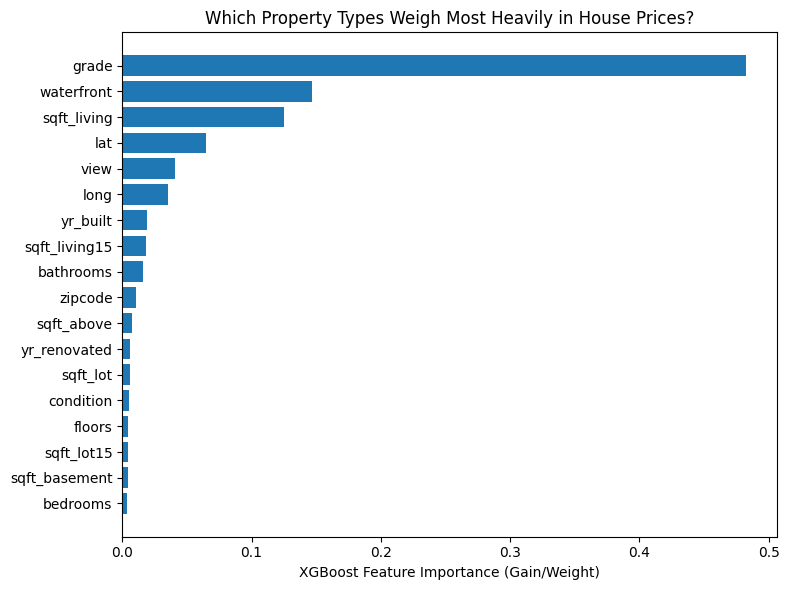

In [19]:
import matplotlib.pyplot as plt
import pandas as pd

feature_importance = pd.DataFrame({
    'Feature': features,
    'Importance': model.feature_importances_
}).sort_values(by='Importance', ascending=True)

plt.figure(figsize=(8, 6))
plt.barh(feature_importance['Feature'], feature_importance['Importance'])
plt.xlabel('XGBoost Feature Importance (Gain/Weight)')
plt.title('Which Property Types Weigh Most Heavily in House Prices?')
plt.tight_layout()

plt.savefig('feature_importance.png', dpi=300)
plt.show()

In [20]:
submission = pd.DataFrame({'price': test_predictions})
file_name = 'team3-module3-predictions.csv'
submission.to_csv(file_name, index=False)